In [3]:
import pandas as pd
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
import sys

# =====================================================================
# 1. SETUP AND DATA PREPARATION
# =====================================================================
# Load the pre-trained embedding model (MiniLM is fast and highly accurate)
print("Downloading AI Model... (This takes a moment on the first run)")
try:
    model = SentenceTransformer('all-MiniLM-L6-v2')
except Exception as e:
    print("Failed to load SentenceTransformer model:", e)
    sys.exit(1)

# Load dataset
try:
    df = pd.read_csv('combined_data.csv')
except FileNotFoundError:
    print("Error: 'combined_data.csv' not found in the working directory.")
    sys.exit(1)

# Ensure required columns exist
if 'title' not in df.columns:
    df['title'] = ''
if 'content' not in df.columns:
    df['content'] = ''

df['text'] = df['title'].fillna('').astype(str) + ". " + df['content'].fillna('').astype(str)

# Define the characters we want to test
characters = {
    'Steve': r'\bsteve\b',
    'Eddie': r'\beddie\b',
    'Eleven': r'\beleven\b|\bel\b',
    'Hopper': r'\bhopper\b'
}

# Group all reviews for each character into one document
char_docs = {}
for char, pattern in characters.items():
    mask = df['text'].str.contains(pattern, case=False, na=False, regex=True)
    if mask.sum() == 0:
        print(f"Warning: no reviews found mentioning '{char}'. Using an empty document.")
        sample_text = ""
    else:
        # We take a sample of text so we don't overload your computer's memory
        sample_text = " ".join(df.loc[mask, 'text'].tolist()[:500])
    char_docs[char] = sample_text

# =====================================================================
# 2. DEFINE THE BRAND PERSONAS
# =====================================================================
# Imagine 3 different companies are looking for a brand ambassador
brands = {
    'Monster Energy (The Rebel)': 'rebellious, bold, edgy, loud, exciting, chaotic, dangerous, intense, rock',
    'Volvo Cars (The Caregiver)': 'protecting, family, safe, emotional, responsible, loving, caring, father figure',
    'Dior (The Mysterious)': 'mysterious, dark, stylish, strange, powerful, magical, unknown, quiet, intense'
}

# =====================================================================
# 3. CONVERT TO EMBEDDINGS (THE "MAP COORDINATES")
# =====================================================================
brand_names = list(brands.keys())
char_names = list(char_docs.keys())

# Encode the text into dense mathematical vectors
print("Converting text to semantic coordinates...")
brand_texts = list(brands.values())
char_texts = list(char_docs.values())

brand_embeddings = model.encode(brand_texts, convert_to_numpy=True)
char_embeddings = model.encode(char_texts, convert_to_numpy=True)

# =====================================================================
# 4. CALCULATE DISTANCE (COSINE SIMILARITY)
# =====================================================================
# Normalize embeddings to unit vectors then compute cosine similarity.
# Cosine similarity between normalized vectors is in [-1, 1]; scale to [0, 1].
brand_embeddings_norm = normalize(brand_embeddings)
char_embeddings_norm = normalize(char_embeddings)

similarity_matrix = cosine_similarity(brand_embeddings_norm, char_embeddings_norm)
similarity_matrix_01 = (similarity_matrix + 1.0) / 2.0

# Put the results into a clean Pandas DataFrame
results_df = pd.DataFrame(similarity_matrix_01, index=brand_names, columns=char_names)

print("\n--- BRAND MATCHMAKING RESULTS (Cosine Similarity scaled to 0..1) ---")
print("Scores range from 0 (No match) to 1 (Perfect match).\n")
print(results_df.round(3)) # Round to 3 decimal places for readability

# =====================================================================
# 5. FIND THE BEST AMBASSADOR
# =====================================================================
print("\n--- RECOMMENDATIONS ---")
for brand in brand_names:
    best_match = results_df.loc[brand].idxmax() # Finds the highest score in the row
    score = results_df.loc[brand].max()
    print(f"For {brand}, the best ambassador is {best_match} (Score: {score:.3f})")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5404.29it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Converting text to semantic coordinates...

--- BRAND MATCHMAKING RESULTS (Cosine Similarity scaled to 0..1) ---
Scores range from 0 (No match) to 1 (Perfect match).

                            Steve  Eddie  Eleven  Hopper
Monster Energy (The Rebel)  0.531  0.600   0.597   0.487
Volvo Cars (The Caregiver)  0.506  0.517   0.540   0.506
Dior (The Mysterious)       0.519  0.599   0.607   0.485

--- RECOMMENDATIONS ---
For Monster Energy (The Rebel), the best ambassador is Eddie (Score: 0.600)
For Volvo Cars (The Caregiver), the best ambassador is Eleven (Score: 0.540)
For Dior (The Mysterious), the best ambassador is Eleven (Score: 0.607)


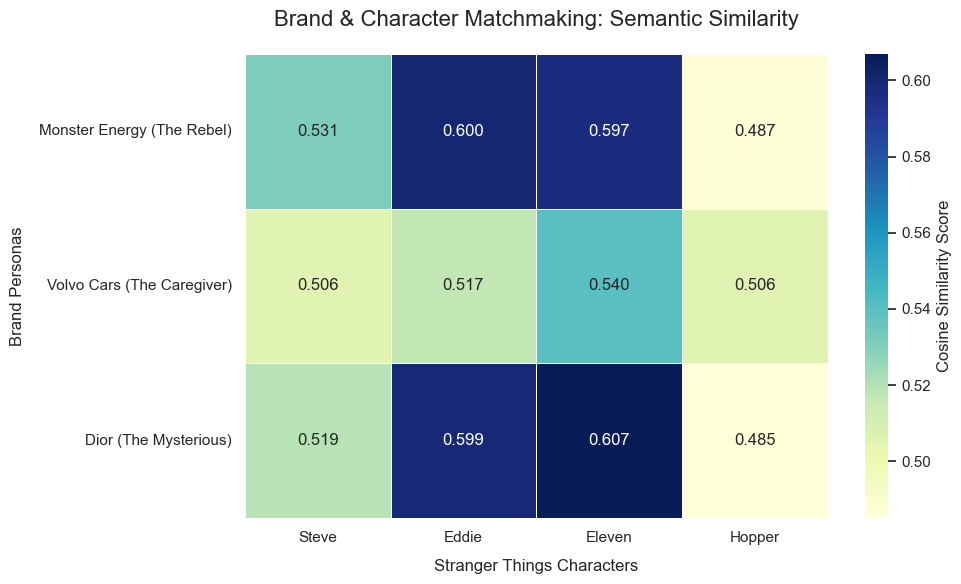

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set up the visual style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Create the heatmap
# annot=True puts the numbers in the boxes. cmap selects the color palette.
heatmap = sns.heatmap(results_df, annot=True, cmap="YlGnBu", fmt=".3f", 
                      linewidths=.5, cbar_kws={'label': 'Cosine Similarity Score'})

# Add professional titles and labels
plt.title('Brand & Character Matchmaking: Semantic Similarity', fontsize=16, pad=20)
plt.xlabel('Stranger Things Characters', fontsize=12, labelpad=10)
plt.ylabel('Brand Personas', fontsize=12, labelpad=10)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()